# Molecular Solubility Prediction with DeepChem

This project uses DeepChem to train and evaluate a graph neural network for predicting molecular solubility from molecular structure. The analysis uses the Delaney solubility dataset and includes model evaluation, prediction error analysis, and examination of molecular features associated woth large prediction errors.

## Environment Setup

In [1]:
!pip install tf_keras

In [2]:
!pip install --pre "deepchem[tensorflow]"
!pip install rdkit

In [3]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "True"

## Imports

In [4]:
import deepchem as dc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import Descriptors
from rdkit.Chem import Lipinski

/usr/local/lib/python3.13/dist-packages/deepchem/feat/smiles_tokenizer.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.
Instructions for updating:
experimental_relax_shapes is deprecated, use reduce_retracing instead
wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.


## Load the Delaney Solubility Dataset

In [5]:
tasks, datasets, transformers = dc.molnet.load_delaney(featurizer='GraphConv')

In [6]:
train_dataset, valid_dataset, test_dataset = datasets

In [7]:
print("Prediction task:", tasks)

print("\nFirst five molecules:")
print(train_dataset.ids[:5])

print("\nFirst five measured solubility values:")
print(train_dataset.y[:5])

Prediction task: ['measured log solubility in mols per litre']

First five molecules:
['CC(C)=CCCC(C)=CC(=O)' 'CCCC=C' 'CCCCCCCCCCCCCC' 'CC(C)Cl' 'CCC(C)CO']

First five measured solubility values:
[[ 0.39041294]
 [ 0.09042128]
 [-2.46434643]
 [ 0.70492033]
 [ 1.15974639]]


Each sample represents a molecule. The molecule IDs are stored as SMILES strings, while the target values represent measured molecular solubility.

The dataset is divided into training, validation, and test sets so that model performance can be evaluated on molecules that were not used during training.

## Graph Neural Network

In [8]:
model = dc.models.GraphConvModel(
    n_tasks=1,
    mode='regression',
    dropout=0.2,
    batch_normalize=False
)

In [9]:
model.fit(train_dataset, nb_epoch=100)

0.062261834144592285

## Model Evaluation

In [10]:
metric = dc.metrics.Metric(dc.metrics.pearson_r2_score)

train_score = model.evaluate(
    train_dataset,
    [metric],
    transformers
)

test_score = model.evaluate(
    test_dataset,
    [metric],
    transformers
)

print("Training score:", train_score)
print("Test score:", test_score)

Training score: {'pearson_r2_score': np.float64(0.9329870575622388)}
Test score: {'pearson_r2_score': np.float64(0.7072005411495491)}


In [11]:
predictions = model.predict(test_dataset)

actual = test_dataset.y.flatten()
predicted = predictions.flatten()

## Predicted vs. Actual Solubility

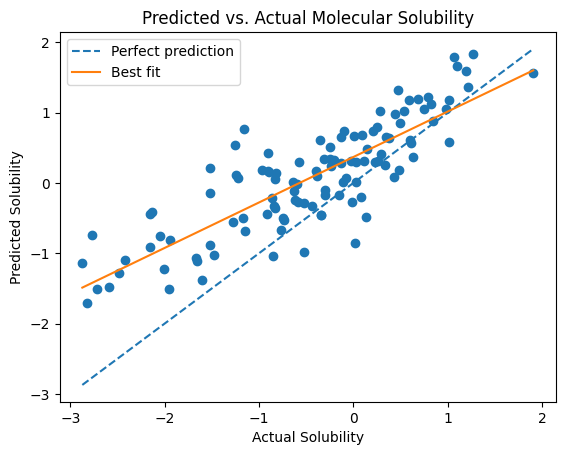

In [12]:
slope, intercept = np.polyfit(actual, predicted, 1)

plt.scatter(actual, predicted)

min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())

# Perfect prediction line
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    label="Perfect prediction"
)

# Best-fit line
x_line = np.linspace(min_val, max_val, 100)
y_line = slope * x_line + intercept

plt.plot(
    x_line,
    y_line,
    label="Best fit"
)

plt.xlabel("Actual Solubility")
plt.ylabel("Predicted Solubility")
plt.title("Predicted vs. Actual Molecular Solubility")
plt.legend()

plt.savefig(
    "predicted_vs_actual_solubility.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The dashed diagonal line represents perfect predictions, where predicted solubility equals the measured value. The best-fit line summarizes the model's overall prediction trend.

Points farther from the diagonal represent larger prediction errors. The fitted line indicates that the model tends to compress predictions toward the center and overpredict solubility for some low-solubility molecules.

## Prediction Error Analysis

In [13]:
errors = predicted - actual
absolute_errors = np.abs(errors)

mean_error = errors.mean()
mae = absolute_errors.mean()

print("Mean prediction error:", mean_error)
print("Mean absolute error:", mae)
print("Best-fit slope:", slope)
print("Best-fit intercept:", intercept)

Mean prediction error: 0.52778026944594
Mean absolute error: 0.6110399296547951
Best-fit slope: 0.646629407743777
Best-fit intercept: 0.3686438008653108


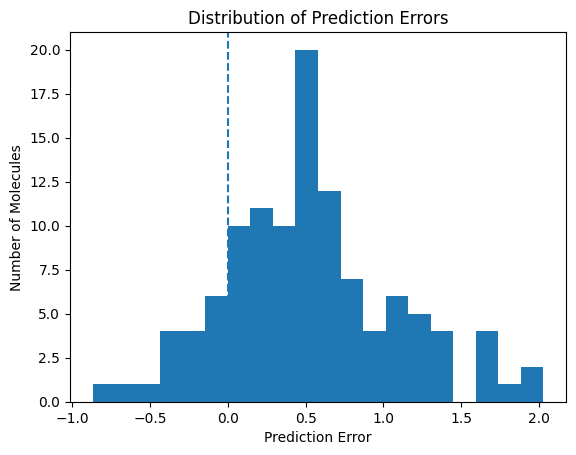

In [14]:
plt.hist(errors, bins=20)

plt.xlabel("Prediction Error")
plt.ylabel("Number of Molecules")
plt.title("Distribution of Prediction Errors")

plt.axvline(0, linestyle="--")

plt.savefig(
    "prediction_error_distribution.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

## Worst-Predicted Molecules

In [15]:
absolute_errors = np.abs(errors)

worst_indices = np.argsort(absolute_errors)[-10:][::-1]

for i in worst_indices:
    print("Molecule:", test_dataset.ids[i])
    print("Predicted:", predicted[i])
    print("Actual:", actual[i])
    print("Absolute error:", absolute_errors[i])
    print()

Molecule: CCOc1ccc(cc1)C(C)(C)COCc3cccc(Oc2ccccc2)c3
Predicted: -0.7453348
Actual: -2.7740152379842105
Absolute error: 2.0286804339261355

Molecule: ClC1(C(=O)C2(Cl)C3(Cl)C14Cl)C5(Cl)C2(Cl)C3(Cl)C(Cl)(Cl)C45Cl
Predicted: 0.76012796
Actual: -1.157447266021587
Absolute error: 1.9175752276571767

Molecule: CN(C=Nc1ccc(C)cc1C)C=Nc2ccc(C)cc2C
Predicted: 0.5333348
Actual: -1.2595412025927073
Absolute error: 1.7928759942530161

Molecule: c1cc2cccc3c4cccc5cccc(c(c1)c23)c54
Predicted: -1.1347175
Actual: -2.8727221719202705
Absolute error: 1.738004707473249

Molecule: Cc1ccc(OP(=O)(Oc2cccc(C)c2)Oc3ccccc3C)cc1
Predicted: 0.21695226
Actual: -1.5208242630116886
Absolute error: 1.737776527320618

Molecule: ClC1=C(Cl)C(Cl)(C(=C1Cl)Cl)C2(Cl)C(=C(Cl)C(=C2Cl)Cl)Cl
Predicted: -0.41422868
Actual: -2.134355597477
Absolute error: 1.7201269197273663

Molecule: C1C(O)CCC2(C)CC3CCC4(C)C5(C)CC6OCC(C)CC6OC5CC4C3C=C21
Predicted: -0.44133097
Actual: -2.154677613287366
Absolute error: 1.7133466439537175

Molecule: 

The molecules below represent the largest prediction errors in the test set. Examining these cases helps identify structural features that may be associated with poor model performance.

In [16]:
worst_molecules = []

for i in worst_indices:
    smiles = test_dataset.ids[i]
    mol = Chem.MolFromSmiles(smiles)

    if mol is not None:
        worst_molecules.append(mol)

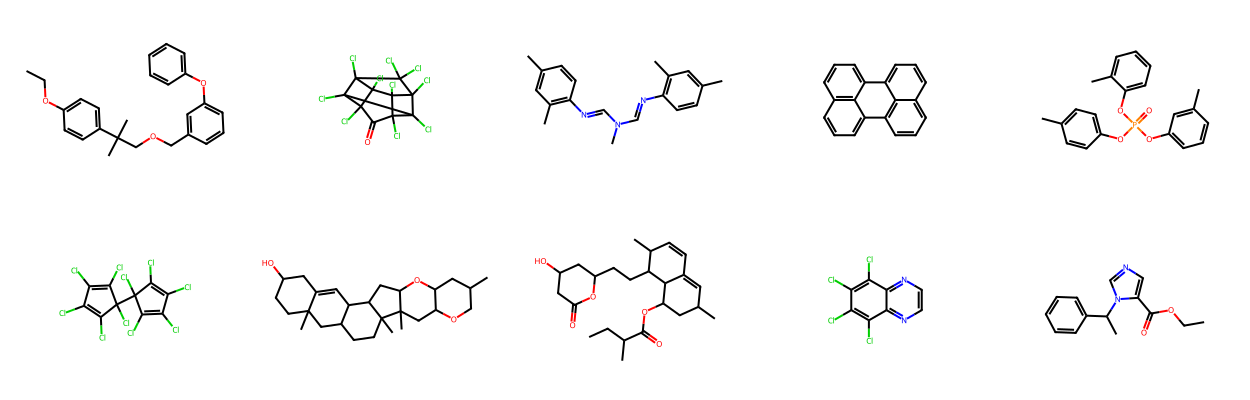

In [17]:
img = Draw.MolsToGridImage(
    worst_molecules,
    molsPerRow=5,
    subImgSize=(250, 200)
)

img.save("worst_predicted_molecules.png")

img

The worst-predicted molecules include several large, ring-rich, and hydrophobic-looking structures. This suggests that the model may have more difficulty accurately predicting solubility for certain structurally complex compounds.

## Molecular Descriptor Analysis

In [18]:
descriptor_rows = []

for i in worst_indices:
    smiles = test_dataset.ids[i]
    mol = Chem.MolFromSmiles(smiles)

    if mol is not None:
        descriptor_rows.append({
            "SMILES": smiles,
            "Predicted Solubility": predicted[i],
            "Actual Solubility": actual[i],
            "Absolute Error": absolute_errors[i],
            "Molecular Weight": Descriptors.MolWt(mol),
            "LogP": Descriptors.MolLogP(mol),
            "Aromatic Rings": Lipinski.NumAromaticRings(mol),
            "H-Bond Donors": Lipinski.NumHDonors(mol),
            "H-Bond Acceptors": Lipinski.NumHAcceptors(mol)
        })

descriptor_table = pd.DataFrame(descriptor_rows)

descriptor_table.to_csv(
    "worst_predicted_molecules.csv",
    index=False
)

descriptor_table

,SMILES,Predicted Solubility,Actual Solubility,Absolute Error,Molecular Weight,LogP,Aromatic Rings,H-Bond Donors,H-Bond Acceptors
0,CCOc1ccc(cc1)C(C)(C)COCc3cccc(Oc2ccccc2)c3,-0.745335,-2.774015,2.028680,376.496,6.37200,3,0,3
1,ClC1(C(=O)C2(Cl)C3(Cl)C14Cl)C5(Cl)C2(Cl)C3(Cl)...,0.760128,-1.157447,1.917575,490.639,4.61820,0,0,1
2,CN(C=Nc1ccc(C)cc1C)C=Nc2ccc(C)cc2C,0.533335,-1.259541,1.792876,293.414,4.87188,2,0,2
3,c1cc2cccc3c4cccc5cccc(c(c1)c23)c54,-1.134717,-2.872722,1.738005,252.316,5.73720,5,0,0
4,Cc1ccc(OP(=O)(Oc2cccc(C)c2)Oc3ccccc3C)cc1,0.216952,-1.520824,1.737777,368.369,6.25676,3,0,4
5,ClC1=C(Cl)C(Cl)(C(=C1Cl)Cl)C2(Cl)C(=C(Cl)C(=C2...,-0.414229,-2.134356,1.720127,474.640,7.72560,0,0,0
6,C1C(O)CCC2(C)CC3CCC4(C)C5(C)CC6OCC(C)CC6OC5CC4...,-0.441331,-2.154678,1.713347,414.630,5.50880,0,1,3
7,CCC(C)C(=O)OC2CC(C)C=C3C=CC(C)C(CCC1CC(O)CC(=O...,-0.143503,-1.518405,1.374901,404.547,4.19550,0,1,5
8,c2(Cl)c(Cl)c(Cl)c1nccnc1c2(Cl),0.115431,-1.240187,1.355618,267.930,4.24340,2,0,2
9,CCOC(=O)c1cncn1C(C)c2ccccc2,0.431315,-0.903906,1.335221,244.294,2.66910,2,0,3


The descriptor table provides a closer look at the molecular properties of the compounds with the largest prediction errors.

Properties such as molecular weight, LogP, aromatic ring count, and hydrogen-bonding capacity may help explain why some molecules are more difficult for the model to predict accurately.

## Model Summary

In [19]:
summary_table = pd.DataFrame({
    "Metric": [
        "Training Pearson R²",
        "Test Pearson R²",
        "Mean Prediction Error",
        "Mean Absolute Error",
        "Best-Fit Slope",
        "Best-Fit Intercept"
    ],
    "Value": [
        train_score["pearson_r2_score"],
        test_score["pearson_r2_score"],
        mean_error,
        mae,
        slope,
        intercept
    ]
})

summary_table.to_csv(
    "model_summary.csv",
    index=False
)

summary_table

,Metric,Value
0,Training Pearson R²,0.932987
1,Test Pearson R²,0.707201
2,Mean Prediction Error,0.527780
3,Mean Absolute Error,0.611040
4,Best-Fit Slope,0.646629
5,Best-Fit Intercept,0.368644


## Conclusion

In this project, the graph neural network was able to predict solubility with reasonably stong accuracy on unseen data with a test Pearson R² of around 0.7. However, the model to have a tendency to overpredict solubilty. The largest errors tended to happen on molecules with more larger and complex molecular structures,suggesting that these types of compounds may be more difficult for the model to predict accurately.